<a href="https://colab.research.google.com/github/rizalrfli/PCVK_GANJIL-2026/blob/main/Week7_D2_OCR.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 7 – D2. Tugas Kelompok: OCR Kartu Identitas (Tesseract)
**Pengolahan Citra dan Visi Komputer – Jurusan Teknologi Informasi**

**Latihan:** Perbandingan pembacaan teks pada citra berwarna dan hasil segmentasi (Otsu & Adaptive Thresholding).

Anggota kelompok:
1. Anggota 1 – Afrizal Rafli Kusuma Wardana (NIM 244107020007)
2. Anggota 2 – Marsyalia Fernanda (NIM 244107020133)



## 0. Instal Tesseract + model bahasa Indonesia

In [1]:
!apt-get -qq update
!apt-get -qq install -y tesseract-ocr tesseract-ocr-ind
!pip -q install pytesseract

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package tesseract-ocr-ind.
(Reading database ... 122815 files and directories currently installed.)
Preparing to unpack .../tesseract-ocr-ind_1%3a4.1.0-2_all.deb ...
Unpacking tesseract-ocr-ind (1:4.1.0-2) ...
Setting up tesseract-ocr-ind (1:4.1.0-2) ...


## 1. Import library & konfigurasi

In [2]:
import os, re, base64, difflib
import cv2 as cv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pytesseract
from pytesseract import Output

# ---- Konfigurasi (SAMA untuk ketiga citra agar perbandingan konsisten) ----
LANG      = 'ind'        # model bahasa Indonesia
PSM       = 11           # page segmentation mode: sparse text (teks tersebar di kartu)
CONF_MIN  = 60           # batas confidence untuk kotak hijau
LEBAR     = 1600         # lebar standar citra (px); tinggi mengikuti rasio asli
ADA_BLOCK = 51           # ukuran jendela adaptive threshold (ganjil)
ADA_C     = 10           # konstanta C adaptive threshold

# Jika model 'ind' belum terpasang, pakai 'eng' (hasil tetap dibandingkan secara konsisten)
if LANG not in pytesseract.get_languages(config=''):
    print("Model 'ind' tidak ditemukan -> memakai 'eng'")
    LANG = 'eng'
CONFIG = f'--psm {PSM}'
print('Tesseract', pytesseract.get_tesseract_version(), '| lang =', LANG, '| config =', CONFIG)

Tesseract 5.3.4 | lang = ind | config = --psm 11


## 2. Siapkan gambar (tertanam, tanpa Drive)
Sel di bawah menulis dua citra kartu ke folder lokal `ktm_data/`.
Ingin memakai gambar lain? Ganti `FILE_ANGGOTA` dengan hasil `files.upload()` dari Colab.

In [3]:
#@title Siapkan gambar kartu (sudah tertanam, tidak perlu diubah)
import base64, os
os.makedirs('ktm_data', exist_ok=True)
DATA_GAMBAR = {
    'anggota1.jpg': "...",
    'anggota2.jpg': "...",
}
for nama_file, data in DATA_GAMBAR.items():
    with open(os.path.join('ktm_data', nama_file), 'wb') as f:
        f.write(base64.b64decode(data))
print(os.listdir('ktm_data'))

['anggota2.jpg', 'anggota1.jpg']


## 3. Data anggota & teks acuan (10 kata/angka yang terlihat jelas)
Acuan dipilih dari tulisan sebenarnya pada kartu: 4 item di latar **putih** dan 6 item di latar **biru** (huruf kuning/putih), agar ukuran dan warna latar beragam.

In [4]:
ANGGOTA = [
    {'label': 'Anggota 1', 'file': 'ktm_data/anggota1.jpg',
     'acuan': [('POLITEKNIK', 'putih'), ('NEGERI', 'putih'), ('MALANG', 'putih'), ('BNI', 'putih'),
               ('VALID', 'biru'), ('AFRIZAL', 'biru'), ('KUSUMA', 'biru'),
               ('244107020007', 'biru'), ('TEKNIK', 'biru'), ('INFORMATIKA', 'biru')]},
    {'label': 'Anggota 2', 'file': 'ktm_data/anggota2.jpg',
     'acuan': [('POLITEKNIK', 'putih'), ('NEGERI', 'putih'), ('MALANG', 'putih'), ('BNI', 'putih'),
               ('VALID', 'biru'), ('MARSYALIA', 'biru'), ('FERNANDA', 'biru'),
               ('244107020133', 'biru'), ('TEKNIK', 'biru'), ('INFORMATIKA', 'biru')]},
]
METODE = ['Berwarna asli', 'Segmentasi Otsu', 'Segmentasi Adaptive']

## 4. Fungsi bantu
- `siapkan_citra` : resize ke ukuran sama → grayscale → Otsu (dengan Gaussian blur 5×5) dan Adaptive Gaussian.
- `ocr_*`         : `image_to_string` dan `image_to_data` (bahasa & `--psm` sama untuk semua citra).
- `cocokkan`      : mencari item acuan pada **teks hasil OCR** (huruf besar/kecil & spasi di awal/akhir diabaikan).

In [5]:
def siapkan_citra(path):
    bgr = cv.imread(path)
    h, w = bgr.shape[:2]
    bgr = cv.resize(bgr, (LEBAR, int(round(h * LEBAR / w))), interpolation=cv.INTER_CUBIC)
    rgb = cv.cvtColor(bgr, cv.COLOR_BGR2RGB)
    gray = cv.cvtColor(bgr, cv.COLOR_BGR2GRAY)                       # grayscale dulu
    T, otsu = cv.threshold(cv.GaussianBlur(gray, (5, 5), 0), 0, 255,
                           cv.THRESH_BINARY + cv.THRESH_OTSU)       # Otsu
    adaptif = cv.adaptiveThreshold(cv.GaussianBlur(gray, (3, 3), 0), 255,
                                   cv.ADAPTIVE_THRESH_GAUSSIAN_C, cv.THRESH_BINARY,
                                   ADA_BLOCK, ADA_C)                # Adaptive
    return {'Berwarna asli': rgb, 'Segmentasi Otsu': otsu, 'Segmentasi Adaptive': adaptif}, T


def ocr_teks(citra):
    return pytesseract.image_to_string(citra, lang=LANG, config=CONFIG)


def ocr_data(citra):
    d = pytesseract.image_to_data(citra, lang=LANG, config=CONFIG, output_type=Output.DICT)
    kata = []
    for i in range(len(d['text'])):
        teks = d['text'][i].strip()
        conf = float(d['conf'][i])
        if teks and conf >= 0:
            kata.append({'teks': teks, 'conf': conf,
                         'x': d['left'][i], 'y': d['top'][i], 'w': d['width'][i], 'h': d['height'][i]})
    return kata


def gambar_kotak(citra, kata, conf_min=CONF_MIN):
    out = cv.cvtColor(citra, cv.COLOR_GRAY2RGB) if citra.ndim == 2 else citra.copy()
    n = 0
    for k in kata:
        if k['conf'] > conf_min:
            cv.rectangle(out, (k['x'], k['y']), (k['x'] + k['w'], k['y'] + k['h']), (0, 255, 0), 2)
            n += 1
    return out, n


def token_ocr(teks):
    # pecah teks hasil OCR menjadi token (hapus tanda baca di awal/akhir, huruf kecil)
    return [t.strip(".,:;|!'\"()[]").lower() for t in teks.split() if t.strip(".,:;|!'\"()[]")]


def cocokkan(item, teks):
    tokens = token_ocr(teks)
    if item.lower() in tokens:
        return item, True
    # token terdekat (panjang tidak jauh berbeda) hanya untuk ditampilkan sebagai "hasil OCR yang salah"
    kandidat = [t for t in tokens if abs(len(t) - len(item)) <= max(2, len(item) // 2)]
    mirip = difflib.get_close_matches(item.lower(), kandidat, n=1, cutoff=0.6)
    return (mirip[0].upper() if mirip else '(tidak terbaca)'), False

## 5. Jalankan: siapkan 3 citra, OCR, dan hitung hasil

In [6]:
HASIL = []     # satu elemen per anggota
for a in ANGGOTA:
    citra, T_otsu = siapkan_citra(a['file'])
    r = {'label': a['label'], 'citra': citra, 'T_otsu': T_otsu, 'metode': {}}
    for m in METODE:
        teks = ocr_teks(citra[m])
        kata = ocr_data(citra[m])
        kotak, n_kotak = gambar_kotak(citra[m], kata)
        r['metode'][m] = {'teks': teks, 'kata': kata, 'kotak': kotak, 'n_kotak': n_kotak,
                          'conf_rata': float(np.mean([k['conf'] for k in kata])) if kata else 0.0}
    HASIL.append(r)
    print(a['label'], '| ukuran citra:', citra['Berwarna asli'].shape[:2], '| T Otsu =', T_otsu)

Anggota 1 | ukuran citra: (958, 1600) | T Otsu = 166.0
Anggota 2 | ukuran citra: (1016, 1600) | T Otsu = 147.0


### 5.1 Tiga citra untuk dibandingkan (ukuran sama)

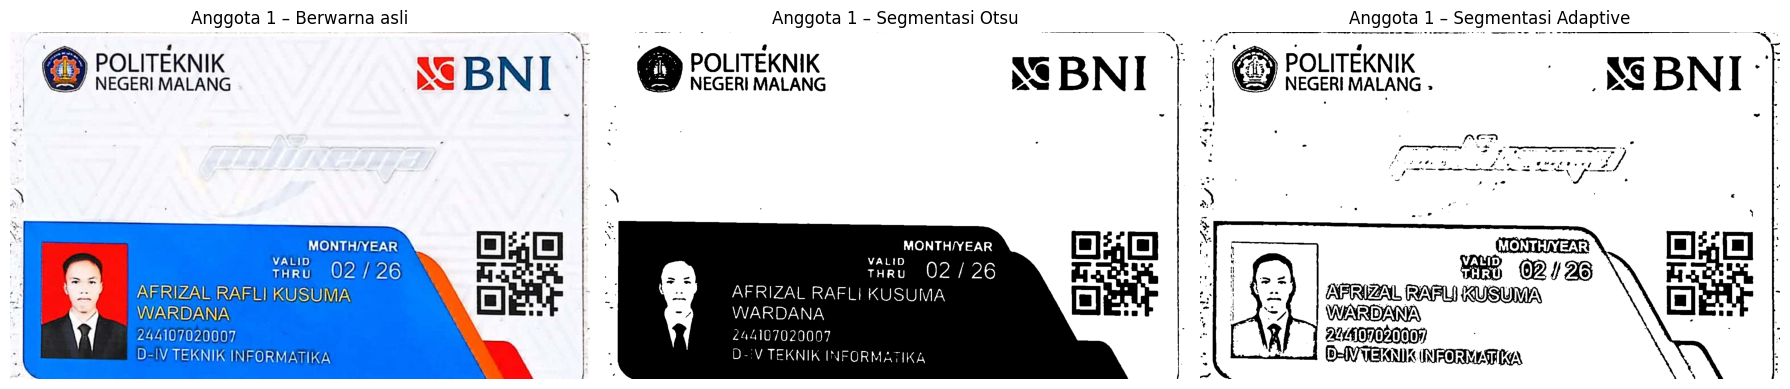

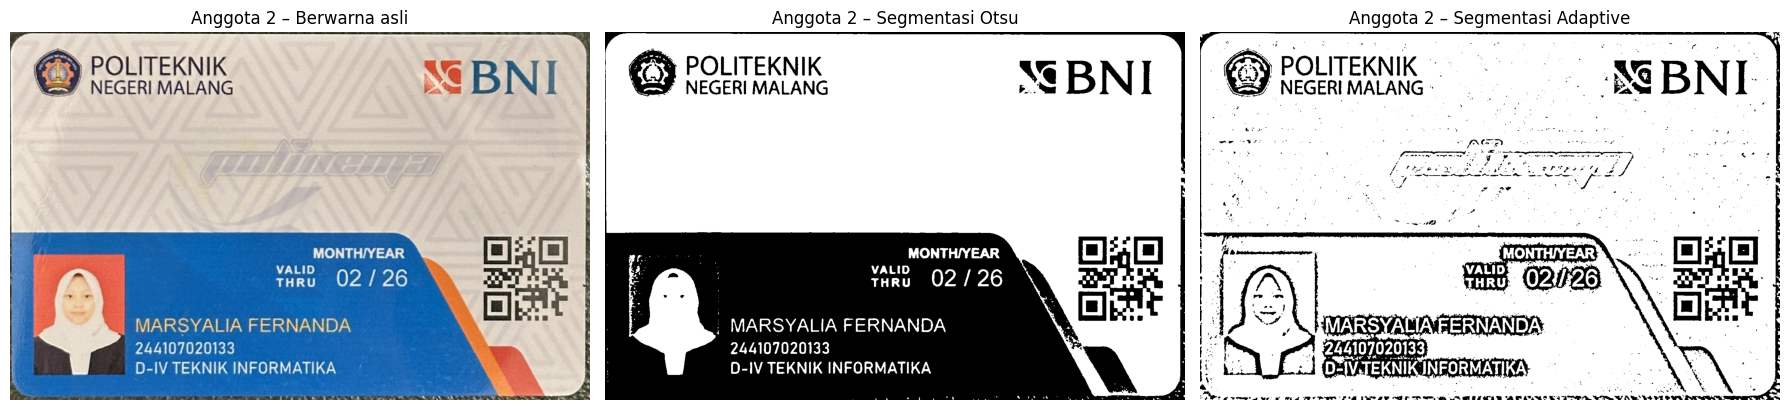

In [7]:
for r in HASIL:
    plt.figure(figsize=(18, 4.2))
    for i, m in enumerate(METODE):
        plt.subplot(1, 3, i+1)
        plt.imshow(r['citra'][m], cmap=None if i == 0 else 'gray')
        plt.title('%s – %s' % (r['label'], m)), plt.axis('off')
    plt.tight_layout(), plt.show()

### 5.2 Hasil pembacaan teks – `image_to_string()`

In [13]:
for r in HASIL:
    for m in METODE:
        print('=' * 50)
        print(f" {r['label']} | {m} ".center(50, '='))
        print('=' * 50)

        # Membersihkan baris kosong dan spasi berlebih
        mentah = r['metode'][m]['teks'].strip().split('\n')
        bersih = []
        for baris in mentah:
            baris_bersih = baris.strip()
            # Abaikan baris yang hanya berisi karakter noise/tanda baca tunggal
            if baris_bersih and not re.match(r'^[\s.,:;|!\'"()\[\]\\#—_\-~*+=\d\?¿«»]*$', baris_bersih):
                bersih.append(baris_bersih)
            elif re.search(r'\d{12}', baris_bersih):  # Tetap pertahankan jika ada NIM
                bersih.append(baris_bersih)

        print('\n'.join(bersih))
        print() # baris kosong pemisah antar metode

=========== Anggota 1 | Berwarna asli ============
PE,
G5
Saha
h
| POLITEKNIK
NEGERI MALANG
SBNI
MO! N: 'k IYEA 2 3
VALID
02/26
THRU
ARRIZAL RAFI KUSUMA
AVAYAN BI DJANNYAN
241107020007.
D-IV TEK
K INFORMATIKA

========== Anggota 1 | Segmentasi Otsu ===========
Naa
Pe POLITEKNIK
NEGERI MALANG
SSBNI |
MONTH/YEAR
VALID
orO
THRU
02/26
AFRIZAL RAFLI KUSUMA
WARDANA
as
244107020007
D-'V TEKNIK INFORMATIKA

======== Anggota 1 | Segmentasi Adaptive =========
MM —
knanaata
POLITEKNIK
NEGERI MALANG
NGBNI
—A
ai
El
TES
SL NY
oriO)
I
TN UMMO22/P2 63
AAL KUSUMA
me:
Teu
Nang INTERN

=========== Anggota 2 | Berwarna asli ============
AN POLITEKNIK
# NEGERI MALANG
“eBNI
Oo
fm
al
Ha
AR SYALIA FERNANDA
TUK wu 7 Tt ntu Tut "en Ten. lp Tae Tt Tn &

========== Anggota 2 | Segmentasi Otsu ===========
“3 POLITEKNIK
7 NEGERI MALANG
“BNI
MONTH/YEAR
o
Im)
THRU
VALID
02/26
Gia
MARSYALIA FERNANDA
244107020133
D-IV TEKNIK INFORMATIKA

======== Anggota 2 | Segmentasi Adaptive =========
POLITEKNIK «—
o
NEGERI MALANG :

### 5.3 Area teks yang dikenali – `image_to_data()` + kotak hijau (confidence > 60)

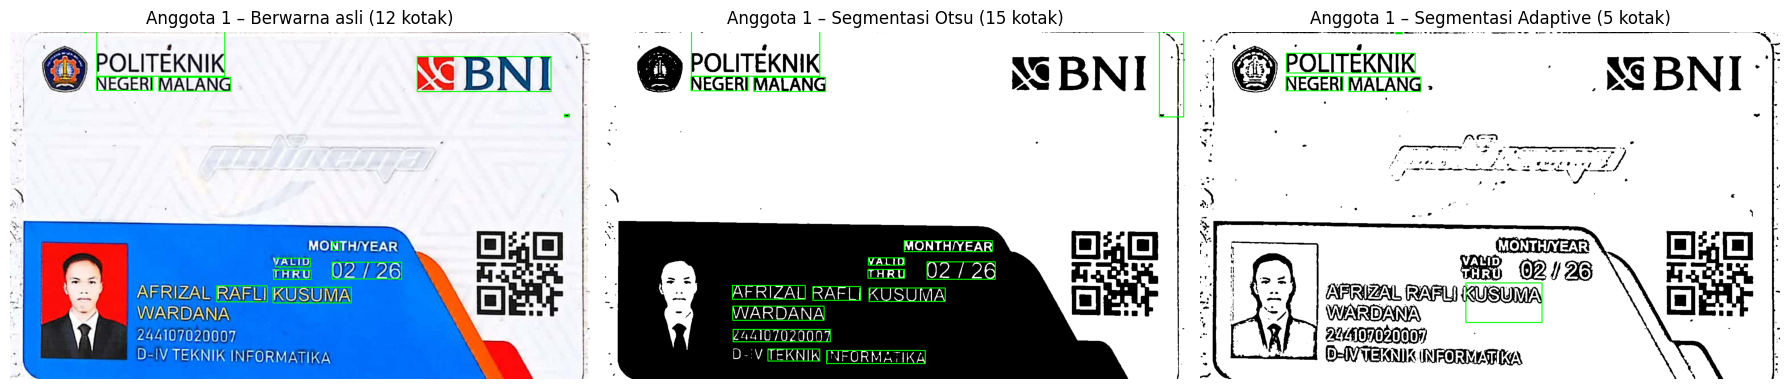

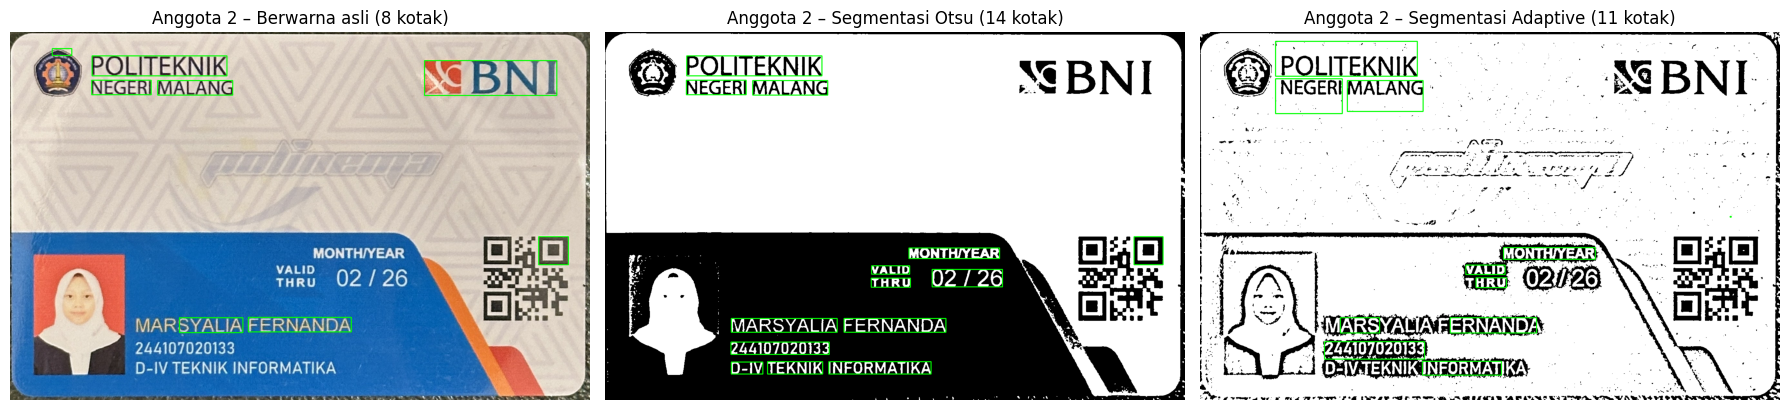

In [9]:
for r in HASIL:
    plt.figure(figsize=(18, 4.6))
    for i, m in enumerate(METODE):
        plt.subplot(1, 3, i+1)
        plt.imshow(r['metode'][m]['kotak'])
        plt.title('%s – %s (%d kotak)' % (r['label'], m, r['metode'][m]['n_kotak'])), plt.axis('off')
    plt.tight_layout(), plt.show()

### 5.4 Tabel perbandingan (10 kata/angka acuan)
Sel berisi kata hasil OCR; **✓** = cocok persis, **✗** = tidak cocok (ditampilkan kata terdekat bila ada, atau *(tidak terbaca)*).

In [10]:
pd.set_option('display.width', 200)
pd.set_option('display.max_colwidth', 40)

TABEL, BENAR = [], []          # BENAR: baris detail untuk ringkasan & analisis
for r in HASIL:
    a = [x for x in ANGGOTA if x['label'] == r['label']][0]
    baris = []
    for no, (item, latar) in enumerate(a['acuan'], 1):
        row = {'No.': no, 'Teks sebenarnya': item, 'Latar': latar}
        for m, kolom in zip(METODE, ['OCR citra berwarna', 'OCR Otsu', 'OCR Adaptive']):
            hasil, ok = cocokkan(item, r['metode'][m]['teks'])
            row[kolom] = hasil + (' ✓' if ok else ' ✗')
            BENAR.append({'anggota': r['label'], 'metode': m, 'item': item, 'latar': latar,
                          'ocr': hasil, 'cocok': ok})
        baris.append(row)
    df = pd.DataFrame(baris)
    TABEL.append(df)
    print('\n>>> Tabel', r['label'])
    display(df)


>>> Tabel Anggota 1


,No.,Teks sebenarnya,Latar,OCR citra berwarna,OCR Otsu,OCR Adaptive
0,1,POLITEKNIK,putih,POLITEKNIK ✓,POLITEKNIK ✓,POLITEKNIK ✓
1,2,NEGERI,putih,NEGERI ✓,NEGERI ✓,NEGERI ✓
2,3,MALANG,putih,MALANG ✓,MALANG ✓,MALANG ✓
3,4,BNI,putih,SBNI ✗,SSBNI ✗,NGBNI ✗
4,5,VALID,biru,VALID ✓,VALID ✓,(tidak terbaca) ✗
5,6,AFRIZAL,biru,ARRIZAL ✗,AFRIZAL ✓,(tidak terbaca) ✗
6,7,KUSUMA,biru,KUSUMA ✓,KUSUMA ✓,KUSUMA ✓
7,8,244107020007,biru,241107020007 ✗,244107020007 ✓,(tidak terbaca) ✗
8,9,TEKNIK,biru,TEK ✗,TEKNIK ✓,(tidak terbaca) ✗
9,10,INFORMATIKA,biru,INFORMATIKA ✓,INFORMATIKA ✓,(tidak terbaca) ✗



>>> Tabel Anggota 2


,No.,Teks sebenarnya,Latar,OCR citra berwarna,OCR Otsu,OCR Adaptive
0,1,POLITEKNIK,putih,POLITEKNIK ✓,POLITEKNIK ✓,POLITEKNIK ✓
1,2,NEGERI,putih,NEGERI ✓,NEGERI ✓,NEGERI ✓
2,3,MALANG,putih,MALANG ✓,MALANG ✓,MALANG ✓
3,4,BNI,putih,“EBNI ✗,“BNI ✗,BNI ✓
4,5,VALID,biru,(tidak terbaca) ✗,VALID ✓,VALID ✓
5,6,MARSYALIA,biru,SYALIA ✗,MARSYALIA ✓,(tidak terbaca) ✗
6,7,FERNANDA,biru,FERNANDA ✓,FERNANDA ✓,ERNANDA ✗
7,8,244107020133,biru,(tidak terbaca) ✗,244107020133 ✓,244107020133 ✓
8,9,TEKNIK,biru,TEN ✗,TEKNIK ✓,(tidak terbaca) ✗
9,10,INFORMATIKA,biru,(tidak terbaca) ✗,INFORMATIKA ✓,JNFORMAT ✗


### 5.5 Ringkasan kecocokan
`Kecocokan = (jumlah item terbaca tepat / 10) × 100%`. Rata-rata confidence dihitung dari **semua kata** yang dikenali Tesseract (confidence ≥ 0) pada citra tersebut.

In [11]:
df_bnr = pd.DataFrame(BENAR)

def ringkasan(label=None):
    baris = []
    for m in METODE:
        sub = df_bnr[df_bnr.metode == m]
        confs = []
        for r in HASIL:
            if label is None or r['label'] == label:
                confs += [k['conf'] for k in r['metode'][m]['kata']]
        if label is not None:
            sub = sub[sub.anggota == label]
        n_item = len(sub)
        tepat = int(sub.cocok.sum())
        baris.append({'Citra masukan OCR': m, 'Item terbaca tepat': '%d / %d' % (tepat, n_item),
                      'Kecocokan (%)': round(100 * tepat / n_item, 1),
                      'Rata-rata confidence': round(float(np.mean(confs)), 1) if confs else 0.0})
    return pd.DataFrame(baris)

for a in ANGGOTA:
    print('>>> Ringkasan', a['label'])
    display(ringkasan(a['label']))
print('>>> Ringkasan GABUNGAN (kedua anggota, 20 item)')
RINGKAS = ringkasan()
display(RINGKAS)

>>> Ringkasan Anggota 1


,Citra masukan OCR,Item terbaca tepat,Kecocokan (%),Rata-rata confidence
0,Berwarna asli,6 / 10,60.0,52.1
1,Segmentasi Otsu,9 / 10,90.0,71.0
2,Segmentasi Adaptive,4 / 10,40.0,30.0


>>> Ringkasan Anggota 2


,Citra masukan OCR,Item terbaca tepat,Kecocokan (%),Rata-rata confidence
0,Berwarna asli,4 / 10,40.0,32.7
1,Segmentasi Otsu,9 / 10,90.0,75.2
2,Segmentasi Adaptive,6 / 10,60.0,33.2


>>> Ringkasan GABUNGAN (kedua anggota, 20 item)


,Citra masukan OCR,Item terbaca tepat,Kecocokan (%),Rata-rata confidence
0,Berwarna asli,10 / 20,50.0,42.7
1,Segmentasi Otsu,18 / 20,90.0,73.0
2,Segmentasi Adaptive,10 / 20,50.0,32.1


## 6. Pertanyaan analisis (jawaban otomatis dari hasil percobaan)

In [12]:
terbaik = RINGKAS.sort_values('Kecocokan (%)', ascending=False).iloc[0]
print('1. Citra masukan paling tepat (gabungan 20 item):', terbaik['Citra masukan OCR'],
      '-> %s item, kecocokan %.1f%%' % (terbaik['Item terbaca tepat'], terbaik['Kecocokan (%)']))
for a in ANGGOTA:
    rs = ringkasan(a['label'])
    b = rs.sort_values('Kecocokan (%)', ascending=False).iloc[0]
    print('   - %s: %s (%.1f%%)' % (a['label'], b['Citra masukan OCR'], b['Kecocokan (%)']))

print()
print('2. Contoh kesalahan pembacaan (item acuan -> hasil OCR):')
salah = df_bnr[~df_bnr.cocok]
for _, s in salah.head(12).iterrows():
    print('   - [%s | %s] %s -> %s' % (s.anggota, s.metode, s['item'], s.ocr))
print('   (total salah: %d dari %d pembacaan)' % (len(salah), len(df_bnr)))

print()
berwarna = RINGKAS.iloc[0]['Kecocokan (%)']
print('3. Dibanding citra berwarna (%.1f%%):' % berwarna)
for _, rr in RINGKAS.iloc[1:].iterrows():
    selisih = rr['Kecocokan (%)'] - berwarna
    arah = 'MENINGKATKAN' if selisih > 0 else ('MENURUNKAN' if selisih < 0 else 'tidak mengubah')
    print('   - %s %s kecocokan (%+.1f poin)' % (rr['Citra masukan OCR'], arah, selisih))

print()
print('4. Kecocokan (%) menurut warna latar item acuan:')
pv = df_bnr.pivot_table(index='metode', columns='latar', values='cocok', aggfunc='mean') * 100
display(pv.reindex(METODE).round(1))

print('5. Confidence tertinggi vs kecocokan tertinggi:')
c_tinggi = RINGKAS.sort_values('Rata-rata confidence', ascending=False).iloc[0]['Citra masukan OCR']
k_tinggi = terbaik['Citra masukan OCR']
print('   - Confidence rata-rata tertinggi :', c_tinggi)
print('   - Kecocokan tertinggi           :', k_tinggi)
print('   -> %s' % ('SAMA: confidence tinggi sejalan dengan kecocokan.' if c_tinggi == k_tinggi
                     else 'BERBEDA: confidence tinggi belum tentu berarti hasil paling tepat.'))

1. Citra masukan paling tepat (gabungan 20 item): Segmentasi Otsu -> 18 / 20 item, kecocokan 90.0%
   - Anggota 1: Segmentasi Otsu (90.0%)
   - Anggota 2: Segmentasi Otsu (90.0%)

2. Contoh kesalahan pembacaan (item acuan -> hasil OCR):
   - [Anggota 1 | Berwarna asli] BNI -> SBNI
   - [Anggota 1 | Segmentasi Otsu] BNI -> SSBNI
   - [Anggota 1 | Segmentasi Adaptive] BNI -> NGBNI
   - [Anggota 1 | Segmentasi Adaptive] VALID -> (tidak terbaca)
   - [Anggota 1 | Berwarna asli] AFRIZAL -> ARRIZAL
   - [Anggota 1 | Segmentasi Adaptive] AFRIZAL -> (tidak terbaca)
   - [Anggota 1 | Berwarna asli] 244107020007 -> 241107020007
   - [Anggota 1 | Segmentasi Adaptive] 244107020007 -> (tidak terbaca)
   - [Anggota 1 | Berwarna asli] TEKNIK -> TEK
   - [Anggota 1 | Segmentasi Adaptive] TEKNIK -> (tidak terbaca)
   - [Anggota 1 | Segmentasi Adaptive] INFORMATIKA -> (tidak terbaca)
   - [Anggota 2 | Berwarna asli] BNI -> “EBNI
   (total salah: 22 dari 60 pembacaan)

3. Dibanding citra berwarna (50.0%)

latar,biru,putih
metode,,
Berwarna asli,33.3,75.0
Segmentasi Otsu,100.0,75.0
Segmentasi Adaptive,25.0,87.5


5. Confidence tertinggi vs kecocokan tertinggi:
   - Confidence rata-rata tertinggi : Segmentasi Otsu
   - Kecocokan tertinggi           : Segmentasi Otsu
   -> SAMA: confidence tinggi sejalan dengan kecocokan.


### Catatan jawaban (interpretasi)
Angka pasti dapat sedikit berbeda antar versi Tesseract/model bahasa; **sesuaikan kalimat di bawah dengan output Anda**.

1. **Citra paling tepat** – pada percobaan ini **Segmentasi Otsu** (lihat tabel ringkasan 5.5 dan jawaban otomatis nomor 1): kecocokannya tertinggi dibanding citra berwarna dan Adaptive.
2. **Kesalahan umum** – logo `BNI` yang menempel pada simbol logo terbaca `SSBNI`/`NI`/`SMOBNI`; kata di latar biru tidak terbaca atau terpotong (mis. `INFORMATIKA` → `INEORMAT`, NIM tidak terbaca) terutama pada citra Adaptive; dan `TEKNIK` yang tidak terpisah dari teks `D-IV` pada citra berwarna. Daftar lengkap ada pada jawaban otomatis nomor 2.
3. **Segmentasi tidak selalu meningkatkan OCR.** Otsu meningkatkan hasil karena satu ambang global memisahkan latar biru (menjadi hitam pekat) dari huruf kuning/putih (menjadi putih) sekaligus menghilangkan pola samar di latar putih. Adaptive Threshold justru **menurunkan** hasil: pada area biru huruf berwarna terang berubah menjadi garis tepi/huruf berongga dengan bayangan di sekelilingnya, sehingga Tesseract membaca fragmen. Pada latar putih Adaptive tetap baik (sama dengan metode lain).
4. **Warna & pola latar** – huruf gelap di latar putih mudah dibaca oleh ketiga citra. Huruf terang (kuning/putih) di latar biru berkontras rendah pada kanal keabuan, sehingga pada citra berwarna sering salah/tidak terbaca; pola geometris samar di latar putih tidak banyak mengganggu pada Otsu karena berada di atas ambang. Lihat tabel "menurut warna latar" pada nomor 4.
5. **Confidence ≠ ketepatan.** Confidence adalah keyakinan internal Tesseract terhadap tiap kata yang ia kenali, bukan jaminan kata itu benar (mis. `SSBNI` dapat memiliki confidence tinggi namun tidak sama dengan `BNI`). Pada percobaan ini confidence tertinggi dan kecocokan tertinggi kebetulan sama-sama pada Otsu; bandingkan dengan jawaban otomatis nomor 5 pada output Anda.